# 09 · Optional: simulated traffic-signal control with SUMO

> **Scope and honesty statement.**
> * This is a **simulation only**. Nothing in this project connects to real traffic signals, detectors or live traffic feeds.
> * METR-LA alone does **not** contain an intersection, signal plans, turning movements, queues or vehicle counts, so its sensor graph cannot be used directly as a SUMO signal network.
>   We therefore use a small synthetic intersection and illustrate *how* forecasts could inform a policy.
> * **If SUMO is not installed, no simulation results are produced.** The notebook then validates everything that can be validated without SUMO (network and demand files, policy safety logic)
>   and clearly reports the experiment as **not executed**. No numbers are ever filled in by hand.

**Objective.** Compare a **fixed-time** signal plan with a **queue-aware** policy on one simulated intersection under identical, seeded demand, using waiting time,
queue length, throughput and travel time.

**Methodology.**
1. Check whether SUMO, `netconvert` and TraCI are available.
2. Generate the network files and seeded Poisson demand; validate them.
3. Implement both policies on a state machine that enforces signal safety (min/max green, yellow, all-red, no conflicting greens) and test it.
4. *If SUMO is available:* run both policies over several seeds and compare. *Otherwise:* report the experiment as not executed.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import shutil, os, importlib.util, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from src import visualization as viz, evaluation as ev
viz.apply_style()

SIM = config.PROJECT_ROOT / "simulation"
sys.path.insert(0, str(SIM))
import signal_policies as sp
import run_sumo_experiment as rs

## 1 · Is SUMO available?

In [3]:
from importlib import metadata
status = {
    "`sumo` executable": "found" if rs.sumo_binary("sumo") else None,
    "`netconvert` executable": "found" if rs.sumo_binary("netconvert") else None,
    "python package `traci`": "installed" if importlib.util.find_spec("traci") else None,
    "SUMO version (pip `eclipse-sumo`)": metadata.version("eclipse-sumo") if importlib.util.find_spec("sumo") else None,
}
display(pd.DataFrame({"component": list(status), "found": [v if v else "NOT FOUND" for v in status.values()]}))
SUMO_AVAILABLE = all(status[k] for k in ("`sumo` executable", "`netconvert` executable", "python package `traci`"))
print("SUMO usable for the experiment:", SUMO_AVAILABLE)
if not SUMO_AVAILABLE:
    print("-> The simulation sections below will be reported as NOT EXECUTED. See simulation/README.md for installation instructions.")

,component,found
0,`sumo` executable,found
1,`netconvert` executable,found
2,python package `traci`,installed
3,SUMO version (pip `eclipse-sumo`),1.28.0


SUMO usable for the experiment: True


## 2 · Network and demand (generated and validated without SUMO)

A 4-way intersection with one lane per approach (250 m arms, 50 km/h) and **straight-through movements only**, so that two phases (north-south, east-west)
never conflict inside a phase. Demand is seeded Poisson arrivals: the first half-hour is heavier on north-south (500 veh/h per approach vs 200), the second half reversed,
so a pre-timed plan cannot be optimal for both halves.

In [4]:
files = rs.write_network_files()
for p in files:
    root = ET.parse(p).getroot()                                       # raises if the XML is not well formed
    print(f"{p.relative_to(config.PROJECT_ROOT)}: <{root.tag}> with {len(root)} elements")
nodes = ET.parse(rs.CFG / "intersection.nod.xml").getroot()
assert sum(n.get("type") == "traffic_light" for n in nodes) == 1
edges = {e.get("id") for e in ET.parse(rs.CFG / "intersection.edg.xml").getroot()}
assert edges == {f"{a}2C" for a in "NSEW"} | {f"C2{a}" for a in "NSEW"}
cons = [(c.get("from"), c.get("to")) for c in ET.parse(rs.CFG / "intersection.con.xml").getroot()]
assert all(f in edges and t in edges for f, t in cons) and len(cons) == 4
print("network files are well formed and internally consistent (edges referenced by every connection exist)")

simulation/sumo_config/intersection.nod.xml: <nodes> with 5 elements
simulation/sumo_config/intersection.edg.xml: <edges> with 8 elements
simulation/sumo_config/intersection.con.xml: <connections> with 4 elements
network files are well formed and internally consistent (edges referenced by every connection exist)


In [5]:
# Demand check: generated arrivals versus the intended Poisson means
rows = []
for seed in range(5):
    path, counts = rs.generate_routes(seed, 3600)
    rows.append({"seed": seed, **{f"{a}": n for a, n in counts.items()}})
gen = pd.DataFrame(rows).set_index("seed")
expected = {a: sum(rate[a] * (end - start) / 3600 for start, end, rate in rs.demand_profile(3600)) for a in "NSEW"}
print("expected vehicles per approach over 3600 s:", {k: round(v) for k, v in expected.items()})
display(gen)
for a in "NSEW":      # every count within 4 standard deviations of the Poisson mean
    assert abs(gen[a].mean() - expected[a]) < 4 * np.sqrt(expected[a] / len(gen)) + 1, a
print("generated demand matches the intended arrival rates; each seed uses its own random stream:", len({tuple(r) for r in gen.values}) == len(gen))
route_file = rs.OUT / "routes_seed0.rou.xml"
departs = [float(v.get("depart")) for v in ET.parse(route_file).getroot().findall("vehicle")]
assert departs == sorted(departs) and max(departs) < 3600

expected vehicles per approach over 3600 s: {'N': 350, 'S': 350, 'E': 350, 'W': 350}


,N,S,E,W
seed,,,,
0,346,356,332,348
1,345,334,347,354
2,349,330,357,345
3,323,373,352,366
4,343,307,355,353


generated demand matches the intended arrival rates; each seed uses its own random stream: True


## 3 · Signal policies and their safety logic

* **Fixed-time:** 30 s north-south / 30 s east-west, regardless of traffic.
* **Queue-aware:** a green ends when the current approach group has no queue while the other has one (gap-out), or when the other queue exceeds the current one by more than a margin.
  An optional `forecast` hook lets a demand forecast add expected arrivals to the pressure (not used in the baseline experiment).
* **Safety, for both:** the controller (not the policy) enforces minimum green 10 s, maximum green 60 s, yellow 3 s, all-red 2 s and never shows green/yellow to both phases at once.
  The check below runs both policies on scripted and random queue sequences and verifies every constraint on the resulting signal traces.

*The plot shows policy logic on scripted queue counts. It is a unit demonstration, not a performance result.*

all safety constraints hold on 200 random + 1 scripted trace per policy (no conflicting greens, min/max green, yellow, all-red)


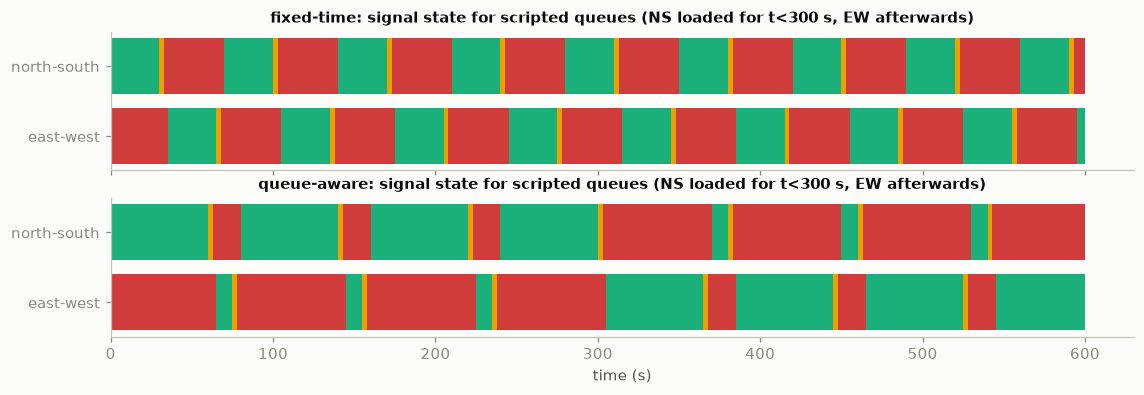

In [6]:
timings = sp.Timings()
scripted = lambda t: {sp.NS: 12 if t < 300 else 1, sp.EW: 1 if t < 300 else 12}      # NS loaded first, EW loaded later
traces = {"fixed-time": sp.run_trace(sp.FixedTimePolicy(30, 30), scripted, 600, timings),
          "queue-aware": sp.run_trace(sp.QueueAwarePolicy(margin=2), scripted, 600, timings)}
rng = np.random.default_rng(0)
for name, policy_factory in (("fixed-time", lambda: sp.FixedTimePolicy(30, 30)), ("queue-aware", lambda: sp.QueueAwarePolicy())):
    for _ in range(200):                                                              # random queue sequences
        q = {t: {sp.NS: int(rng.integers(0, 30)), sp.EW: int(rng.integers(0, 30))} for t in range(1200)}
        sp.check_trace_is_safe(sp.run_trace(policy_factory(), lambda t: q[t], 1200, timings), timings)
    sp.check_trace_is_safe(traces[name], timings)
print("all safety constraints hold on 200 random + 1 scripted trace per policy (no conflicting greens, min/max green, yellow, all-red)")

fig, axes = plt.subplots(2, 1, figsize=(12, 3.6), sharex=True)
colour = {"G": "#1baf7a", "y": "#eda100", "r": "#d03b3b"}
for ax, (name, tr) in zip(axes, traces.items()):
    for k, (phase, y0) in enumerate(((sp.NS, 1), (sp.EW, 0))):
        for t, s in enumerate(tr):
            ax.barh(y0, 1, left=t, color=colour[s[phase]], height=0.8, linewidth=0)
    ax.set_yticks([0, 1], ["east-west", "north-south"]); ax.set_title(f"{name}: signal state for scripted queues (NS loaded for t<300 s, EW afterwards)", fontsize=10); ax.grid(False)
axes[-1].set_xlabel("time (s)")
viz.save_figure(fig, "09_policy_logic_demo"); plt.show()

**Reading the demonstration.** The fixed-time plan alternates 30 s / 30 s whatever the queues are. The queue-aware controller holds the minimum green, keeps serving the loaded approach
until the other queue clearly dominates, and always passes through yellow and all-red before the other phase turns green. Whether this *improves* anything must be measured in the simulator.

## 4 · Simulation experiment

Runs only when SUMO, `netconvert` and TraCI are installed; otherwise it is skipped and **no results are shown**.
Settings: 3,600 s of simulated time, **20 seeds**, both policies on identical demand per seed (same route file, same SUMO seed).
Every simulation step asserts that SUMO displays exactly the signal state chosen by our controller.

In [7]:
SEEDS = range(20)
results = None
if SUMO_AVAILABLE:
    rs.convert_network()
    rows = [rs.run_episode(policy, seed) for seed in SEEDS for policy in ("fixed", "queue_aware")]
    results = pd.DataFrame(rows)
    results.to_csv(config.METRICS_DIR / "sumo_signal_control_results.csv", index=False)
    print("simulation finished:", len(results), "episodes")
else:
    print("NOT EXECUTED: SUMO is not installed in this environment, so there are no simulation results.")

simulation finished: 40 episodes


mean_waiting_time_s       mean_travel_time_s        \
                           mean   std               mean   std   
policy                                                           
fixed                     11.72  0.38              58.04  0.50   
queue_aware                8.26  0.45              55.95  0.77   

            mean_queue_vehicles       max_queue_vehicles        \
                           mean   std               mean   std   
policy                                                           
fixed                      4.54  0.18               19.7  1.42   
queue_aware                3.20  0.22               16.9  1.68   

            completed_trips         
                       mean    std  
policy                              
fixed               1377.35  31.16  
queue_aware         1376.40  31.45

paired over 20 seeds (identical demand per seed); negative difference = queue-aware has the lower value


,mean fixed,mean queue-aware,mean difference (queue-aware - fixed),95% CI low,95% CI high,relative change %,seeds where queue-aware is lower
metric,,,,,,,
mean_waiting_time_s,11.723,8.260,-3.463,-3.709,-3.217,-29.540,20
mean_travel_time_s,58.041,55.950,-2.091,-2.458,-1.724,-3.603,20
mean_queue_vehicles,4.539,3.201,-1.338,-1.431,-1.245,-29.475,20
max_queue_vehicles,19.700,16.900,-2.800,-3.942,-1.658,-14.213,17
completed_trips,1377.350,1376.400,-0.950,-2.678,0.778,-0.069,10


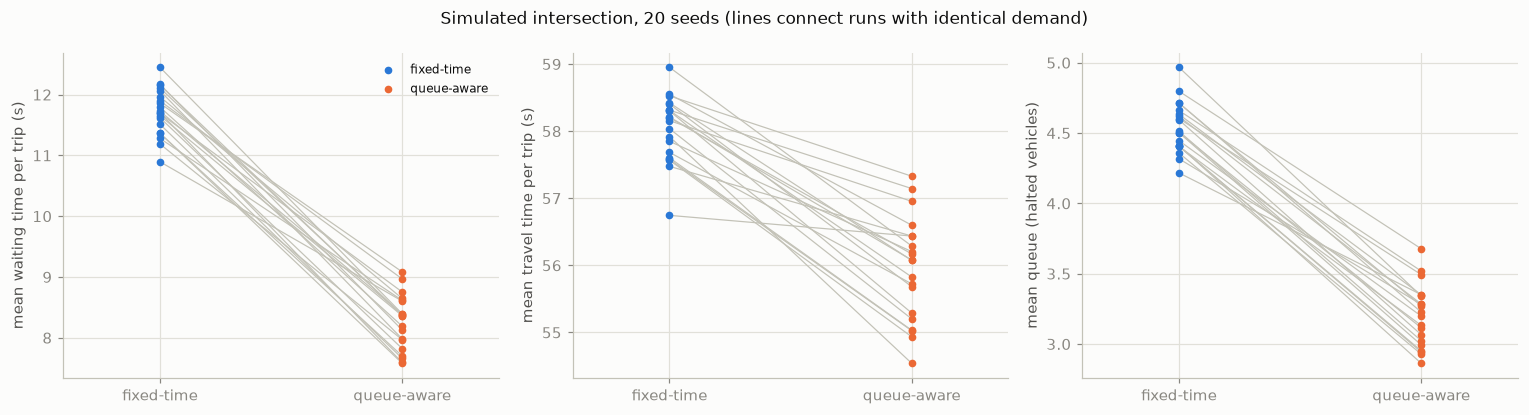

In [8]:
from scipy import stats as st
paired_stats = None
if results is not None:
    metrics_cols = ["mean_waiting_time_s", "mean_travel_time_s", "mean_queue_vehicles", "max_queue_vehicles", "completed_trips"]
    summary = results.groupby("policy")[metrics_cols].agg(["mean", "std"]).round(2)
    display(summary)
    wide = results.pivot(index="seed", columns="policy")
    rows = []
    for m in metrics_cols:
        d = wide[(m, "queue_aware")] - wide[(m, "fixed")]                 # queue-aware minus fixed, paired by seed
        lo, hi = st.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=d.std(ddof=1) / np.sqrt(len(d)))
        rows.append({"metric": m, "mean fixed": wide[(m, "fixed")].mean(), "mean queue-aware": wide[(m, "queue_aware")].mean(),
                     "mean difference (queue-aware - fixed)": d.mean(), "95% CI low": lo, "95% CI high": hi,
                     "relative change %": 100 * d.mean() / wide[(m, "fixed")].mean(), "seeds where queue-aware is lower": int((d < 0).sum())})
    paired_stats = pd.DataFrame(rows).set_index("metric")
    print(f"paired over {len(wide)} seeds (identical demand per seed); negative difference = queue-aware has the lower value")
    display(paired_stats.round(3))
    paired_stats.to_csv(config.METRICS_DIR / "sumo_signal_control_paired.csv")

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    for ax, (m, label) in zip(axes, (("mean_waiting_time_s", "mean waiting time per trip (s)"), ("mean_travel_time_s", "mean travel time per trip (s)"), ("mean_queue_vehicles", "mean queue (halted vehicles)"))):
        for seed in wide.index:
            ax.plot([0, 1], [wide.loc[seed, (m, "fixed")], wide.loc[seed, (m, "queue_aware")]], color="#c3c2b7", lw=0.8)
        ax.scatter(np.zeros(len(wide)), wide[(m, "fixed")], color="#2a78d6", s=16, zorder=3, label="fixed-time")
        ax.scatter(np.ones(len(wide)), wide[(m, "queue_aware")], color="#eb6834", s=16, zorder=3, label="queue-aware")
        ax.set_xticks([0, 1], ["fixed-time", "queue-aware"]); ax.set_xlim(-0.4, 1.4); ax.set_ylabel(label)
    axes[0].legend(fontsize=8); fig.suptitle("Simulated intersection, 20 seeds (lines connect runs with identical demand)", fontsize=11)
    fig.tight_layout(); viz.save_figure(fig, "09_sumo_policy_comparison"); plt.show()
else:
    print("Results table: none (experiment not executed).")

### Interpretation (checked against the results above)

In [9]:
if paired_stats is not None:
    ps_ = paired_stats
    display(ev.report_claims({
        "queue-aware lowers mean waiting time (95% CI entirely below 0)": bool(ps_.loc["mean_waiting_time_s", "95% CI high"] < 0),
        "queue-aware lowers mean waiting time in every seed": bool(ps_.loc["mean_waiting_time_s", "seeds where queue-aware is lower"] == len(SEEDS)),
        "queue-aware lowers mean travel time (95% CI below 0)": bool(ps_.loc["mean_travel_time_s", "95% CI high"] < 0),
        "queue-aware lowers the mean queue (95% CI below 0)": bool(ps_.loc["mean_queue_vehicles", "95% CI high"] < 0),
        "the travel-time reduction is much smaller in relative terms than the waiting-time reduction": bool(abs(ps_.loc["mean_travel_time_s", "relative change %"]) < abs(ps_.loc["mean_waiting_time_s", "relative change %"]) / 3),
        "throughput (completed trips) shows no detectable difference (95% CI contains 0)": bool(ps_.loc["completed_trips", "95% CI low"] <= 0 <= ps_.loc["completed_trips", "95% CI high"]),
    }))
else:
    print("no simulation results: nothing to interpret")

,claim,holds in this run
0,queue-aware lowers mean waiting time (95% CI e...,True
1,queue-aware lowers mean waiting time in every ...,True
2,queue-aware lowers mean travel time (95% CI be...,True
3,queue-aware lowers the mean queue (95% CI belo...,True
4,the travel-time reduction is much smaller in r...,True
5,throughput (completed trips) shows no detectab...,True


**What the simulation shows (for this synthetic scenario only).**

* Under identical, seeded demand the queue-aware controller reduces the average **waiting time** per vehicle and the **queue length** substantially, consistently across all seeds (paired comparison, intervals clearly below zero).
* **Travel time** falls much less in relative terms, because most of a trip is driving along the 250 m arms, not waiting.
* **Throughput** does not change detectably: demand stays below the intersection's capacity, so both controllers eventually serve every arriving vehicle; the queue-aware one serves them with less delay.
* **Fairness caveat.** The fixed-time baseline is a symmetric 30 s / 30 s plan, while the demand is deliberately asymmetric (north-south heavy first, east-west heavy later). A fixed-time plan tuned to each half-hour would likely close part of the gap; we did not optimise it, so the size of the improvement is an upper bound for this scenario rather than a general result.
* **Scope.** One isolated synthetic intersection with straight-through traffic only. The queue-aware policy uses queue counts read directly from the simulator (perfect detection); **the METR-LA forecasts are not used** here (`QueueAwarePolicy.forecast` is the hook). These numbers say nothing about real Los Angeles corridors, and nothing here controls real traffic signals.

## 5 · Status, limitations and plan

| Item | Status |
|---|---|
| Network, demand and policy logic | implemented; files validated; safety logic unit-tested (`tests/test_signal_policies.py`) |
| SUMO simulation and metric comparison | implemented in `simulation/run_sumo_experiment.py`; runs whenever SUMO is available (the delivered run: SUMO 1.28 via `pip install eclipse-sumo traci`, 20 seeds x 2 policies, every step checks that SUMO shows the controller's signal state) |
| Link to the METR-LA forecasts | **not implemented**: METR-LA has no intersection data; the `QueueAwarePolicy.forecast` hook is the integration point |

**Limitations.** One synthetic isolated intersection, straight-through movements only, two phases, synthetic Poisson demand, no pedestrians or turning conflicts,
no driver heterogeneity beyond the default car-following model; results would say nothing about real corridors or about the METR-LA network.

**Plan to extend.** See `simulation/README.md`: check link numbering in `sumo-gui`, run 5-10 seeds per policy, compare paired differences, then feed a short-term demand forecast into the policy hook.